In [1]:
# ==== Cell 1: imports and settings ====
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

PROJECT = Path("/home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim")
DATA_DIR = PROJECT / "data/dataset_20261025_104552_105991"
OUT_DIR = PROJECT / "data/simple_model"
USE_FAKE_DATA = False      # True: build a small fake dataset to test the notebook end to end

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

# Step 0: per-step brain model
STEP_BATCH, STEP_EPOCHS, STEP_LR = 512, 2, 1e-3

# Step 1: sequence model
SEQ_LEN, SEQ_STRIDE = 128, 64
SEQ_BATCH, SEQ_EPOCHS, SEQ_LR = 256, 20, 3e-4

OUT_DIR.mkdir(parents=True, exist_ok=True)
print("device:", DEVICE)

device: cuda


In [2]:
# ==== Cell 2: state layout and the true rule ====
# One state row = one ant at one step (19 numbers).
# ON_FOOD = 0 is assumed; AT_HOME = 1 and CARRYING = 2 match the old notebook.
ON_FOOD, AT_HOME, CARRYING = 0, 1, 2
SEE_FOOD, SEE_HOME = slice(3, 7), slice(7, 11)
SMELL_FOOD, SMELL_HOME = slice(11, 15), slice(15, 19)
N_ACTIONS = 4   # up, down, left, right


def sees_target(s):
    """True where the ant can see its current target (food if searching, home if carrying)."""
    carrying = s[:, CARRYING] > 0.5
    target = np.where(carrying[:, None], s[:, SEE_HOME], s[:, SEE_FOOD])
    return target.max(axis=1) > 0


def signal(s):
    """The 4 numbers the brain uses: the target if visible, otherwise the smell."""
    carrying = s[:, CARRYING] > 0.5
    target = np.where(carrying[:, None], s[:, SEE_HOME], s[:, SEE_FOOD])
    smell = np.where(carrying[:, None], s[:, SMELL_HOME], s[:, SMELL_FOOD])
    return np.where(sees_target(s)[:, None], target, smell)


def best_dir(s):
    return signal(s).argmax(axis=1)


def n_ties(s):
    """How many directions share the top signal. 1 = clear choice, 4 = no signal at all."""
    sig = signal(s)
    return (sig == sig.max(axis=1, keepdims=True)).sum(axis=1)


def true_probs(s, eps):
    """True action probabilities: brain with prob 1-eps (split over tied best dirs), uniform with prob eps."""
    sig = signal(s)
    is_best = sig == sig.max(axis=1, keepdims=True)
    k = is_best.sum(axis=1, keepdims=True)
    eps = np.asarray(eps, dtype=np.float64).reshape(-1, 1)
    return is_best * (1 - eps) / k + eps / N_ACTIONS


def true_entropy(s, eps):
    """Lowest possible loss for each row. Only reachable if the model knows the true eps."""
    p = true_probs(s, eps)
    return -(p * np.log(np.clip(p, 1e-12, None))).sum(axis=1)

In [3]:
# ==== Cell 3 (optional): fake dataset for testing the notebook ====
def make_fake_run(path, eps, seed, T=300, N=20):
    rng = np.random.default_rng(seed)
    rows = T * N
    s = np.zeros((rows, 19), dtype=np.float32)
    s[:, CARRYING] = rng.random(rows) < 0.4
    s[:, AT_HOME] = rng.random(rows) < 0.05
    s[:, ON_FOOD] = rng.random(rows) < 0.05
    s[:, 3:11] = (rng.random((rows, 8)) < 0.03) * rng.integers(1, 6, (rows, 8))   # targets rarely visible
    s[:, 11:19] = (rng.random((rows, 1)) < 0.6) * rng.random((rows, 8)) * 0.5     # smell on 60% of rows

    p = true_probs(s, eps)
    action = np.minimum((rng.random((rows, 1)) > p.cumsum(axis=1)).sum(axis=1), N_ACTIONS - 1)

    s, action = s.reshape(T, N, 19), action.reshape(T, N)
    prev = np.zeros((T, N, 4), dtype=np.float32)
    prev[1:] = np.eye(4, dtype=np.float32)[action[:-1]]
    carrying = s[..., CARRYING] > 0.5

    path.mkdir(parents=True, exist_ok=True)
    np.savez(path / "traj.npz", state=s, action=action, prev_action=prev,
             dec_pick=(s[..., ON_FOOD] > 0.5) & ~carrying,
             dec_drop=(s[..., AT_HOME] > 0.5) & carrying,
             delivered=np.zeros(T + 1), epsilon=eps, seed=seed)


if USE_FAKE_DATA:
    DATA_DIR = Path("fake_data")
    split_seeds = {"train": [0, 1, 2, 3], "val": [4], "test": [5]}
    for split, seeds in split_seeds.items():
        for seed in seeds:
            for eps in np.round(np.arange(0.1, 1.01, 0.1), 1):
                make_fake_run(DATA_DIR / split / f"seed{seed:03d}_eps{eps}",
                              float(eps), seed * 100 + int(eps * 10))
    print("fake data written to", DATA_DIR)

In [4]:
# ==== Cell 4: load runs ====
def load_run(run_dir):
    """One run, kept in (T, N, ...) shape so we still know which ant is which."""
    with np.load(run_dir / "traj.npz") as d:
        return dict(
            name=run_dir.name,
            state=d["state"].astype(np.float32),              # (T, N, 19) raw
            action=d["action"].astype(np.int64),              # (T, N)
            prev_action=d["prev_action"].astype(np.float32),  # (T, N, 4)
            pick=d["dec_pick"].astype(np.float32),            # (T, N)
            drop=d["dec_drop"].astype(np.float32),            # (T, N)
            eps=float(d["epsilon"]),
            seed=int(d["seed"]),
        )


runs = {}
for split in ["train", "val", "test"]:
    run_dirs = sorted(p.parent for p in (DATA_DIR / split).glob("*/traj.npz"))
    runs[split] = [load_run(r) for r in run_dirs]
    eps_values = sorted({r["eps"] for r in runs[split]})
    print(f"{split}: {len(runs[split])} runs   eps values: {eps_values}")

train: 60 runs   eps values: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
val: 20 runs   eps values: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
test: 20 runs   eps values: [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]


In [5]:
# ==== Cell 5: sanity checks per run ====
def check_run(run):
    T, N, D = run["state"].shape
    a = run["action"]
    prev = run["prev_action"]
    has_prev = prev[1:].sum(-1) > 0                       # rows where prev_action is filled in
    prev_matches = (prev[1:].argmax(-1) == a[:-1])[has_prev].mean()
    return dict(run=run["name"], eps=run["eps"], T=T, N=N, D=D,
                action_min=int(a.min()), action_max=int(a.max()),
                any_nan=bool(np.isnan(run["state"]).any()),
                prev_action_matches=round(float(prev_matches), 4))


checks = pd.DataFrame([check_run(r) for split in runs for r in runs[split]])
print(checks.head(10).to_string(index=False))
print()
print("all D == 19:            ", (checks.D == 19).all())
print("actions in 0..3:        ", ((checks.action_min >= 0) & (checks.action_max <= 3)).all())
print("no NaNs:                ", (~checks.any_nan).all())
print("prev_action consistent: ", (checks.prev_action_matches > 0.99).all())

                   run  eps    T   N  D  action_min  action_max  any_nan  prev_action_matches
seed000_eps0.1_p2_a100  0.1 1500 100 19           0           3    False               0.9995
seed000_eps0.2_p2_a100  0.2 1500 100 19           0           3    False               0.9993
seed000_eps0.3_p2_a100  0.3 1500 100 19           0           3    False               0.9994
seed000_eps0.4_p2_a100  0.4 1500 100 19           0           3    False               0.9996
seed000_eps0.5_p2_a100  0.5 1500 100 19           0           3    False               0.9993
seed000_eps0.6_p2_a100  0.6 1500 100 19           0           3    False               0.9999
seed000_eps0.7_p2_a100  0.7 1500 100 19           0           3    False               0.9997
seed000_eps0.8_p2_a100  0.8 1500 100 19           0           3    False               0.9991
seed000_eps0.9_p2_a100  0.9 1500 100 19           0           3    False               0.9983
seed000_eps1.0_p2_a100  1.0 1500 100 19           0         

In [6]:
# ==== Cell 6: does the data follow the rule? ====
# On clear rows (one best direction) the ant should take it with prob (1 - eps) + eps / 4.
rows = []
for r in runs["train"]:
    s = r["state"].reshape(-1, 19)
    a = r["action"].reshape(-1)
    clear = n_ties(s) == 1
    rows.append(dict(eps=r["eps"],
                     follows_rule=(a[clear] == best_dir(s)[clear]).mean(),
                     expected=1 - r["eps"] + r["eps"] / 4,
                     frac_clear_rows=clear.mean()))
print(pd.DataFrame(rows).groupby("eps").mean().round(3))

     follows_rule  expected  frac_clear_rows
eps                                         
0.1         0.925     0.925            0.639
0.2         0.850     0.850            0.651
0.3         0.775     0.775            0.653
0.4         0.701     0.700            0.631
0.5         0.625     0.625            0.638
0.6         0.550     0.550            0.602
0.7         0.475     0.475            0.603
0.8         0.399     0.400            0.574
0.9         0.326     0.325            0.454
1.0         0.249     0.250            0.202


In [7]:
# ==== Cell 7: normalization (used in training AND in the simulator) ====
def normalize(s):
    """Works on any shape (..., 19). See values / 20, each smell block min-max scaled per row."""
    s = s.astype(np.float32).copy()
    s[..., 3:11] /= 20.0
    for blk in (SMELL_FOOD, SMELL_HOME):
        block = s[..., blk]
        lo = block.min(axis=-1, keepdims=True)
        hi = block.max(axis=-1, keepdims=True)
        s[..., blk] = np.where(hi > lo, (block - lo) / np.maximum(hi - lo, 1e-8), 0.0)
    return s


# The rule must give the same answer before and after normalization
s_raw = runs["val"][0]["state"].reshape(-1, 19)
s_norm = normalize(s_raw)
print("best_dir unchanged:", (best_dir(s_raw) == best_dir(s_norm)).mean(), "  (want 1.0)")
print("ties unchanged:    ", (n_ties(s_raw) == n_ties(s_norm)).mean(), "  (want 1.0)")
print("normalized range:  ", s_norm.min(), "to", s_norm.max())

best_dir unchanged: 1.0   (want 1.0)
ties unchanged:     1.0   (want 1.0)
normalized range:   0.0 to 1.0


In [8]:
# ==== Cell 8: flat tables (one row per ant-step) for the Step 0 model ====
def flatten(run_list):
    return dict(
        state=normalize(np.concatenate([r["state"].reshape(-1, 19) for r in run_list])),
        action=np.concatenate([r["action"].reshape(-1) for r in run_list]),
        pick=np.concatenate([r["pick"].reshape(-1) for r in run_list]),
        drop=np.concatenate([r["drop"].reshape(-1) for r in run_list]),
        eps=np.concatenate([np.full(r["action"].size, r["eps"], dtype=np.float32) for r in run_list]),
    )


flat = {split: flatten(runs[split]) for split in runs}
for split, f in flat.items():
    print(f"{split}: {len(f['action']):,} rows   state {f['state'].shape}")

train: 9,000,000 rows   state (9000000, 19)
val: 3,000,000 rows   state (3000000, 19)
test: 3,000,000 rows   state (3000000, 19)


In [9]:
# ==== Cell 9: Step 0 model = the pure brain ====
class DirScorer(nn.Module):
    """Scores each direction with the same small network, so all 4 directions are treated alike."""
    def __init__(self, hidden=64):
        super().__init__()
        self.score = nn.Sequential(nn.Linear(7, hidden), nn.ReLU(),
                                   nn.Linear(hidden, hidden), nn.ReLU(),
                                   nn.Linear(hidden, 1))
        self.pick_head = nn.Linear(3, 1)
        self.drop_head = nn.Linear(3, 1)

    def forward(self, x):                                    # x: (B, 19)
        flags = x[:, :3]                                     # (B, 3)
        per_dir = torch.stack([x[:, SEE_FOOD], x[:, SEE_HOME],
                               x[:, SMELL_FOOD], x[:, SMELL_HOME]], dim=-1)          # (B, 4 dirs, 4)
        tokens = torch.cat([per_dir, flags[:, None, :].expand(-1, 4, -1)], dim=-1)   # (B, 4, 7)
        a_logit = self.score(tokens).squeeze(-1)             # (B, 4)
        return a_logit, self.pick_head(flags).squeeze(-1), self.drop_head(flags).squeeze(-1)


def mixture_nll(a_logit, action, eps):
    """-log P(action) when the ant follows the brain with prob 1-eps and moves uniformly with prob eps."""
    p_brain = a_logit.softmax(-1).gather(1, action[:, None]).squeeze(1)
    return -torch.log((1 - eps) * p_brain + eps / N_ACTIONS + 1e-12)

In [10]:
# ==== Cell 9b: Step 0 model that only sees the blocks the rule uses ====
class DirScorerRelevant(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.score = nn.Sequential(nn.Linear(5, hidden), nn.ReLU(),
                                   nn.Linear(hidden, hidden), nn.ReLU(),
                                   nn.Linear(hidden, 1))
        self.pick_head = nn.Linear(3, 1)
        self.drop_head = nn.Linear(3, 1)

    def forward(self, x):                                        # x: (B, 19)
        flags = x[:, :3]
        carrying = flags[:, CARRYING:CARRYING + 1] > 0.5         # (B, 1)
        target = torch.where(carrying, x[:, SEE_HOME], x[:, SEE_FOOD])       # (B, 4)
        smell = torch.where(carrying, x[:, SMELL_HOME], x[:, SMELL_FOOD])    # (B, 4)
        per_dir = torch.stack([target, smell], dim=-1)                       # (B, 4, 2)
        tokens = torch.cat([per_dir, flags[:, None, :].expand(-1, 4, -1)], dim=-1)  # (B, 4, 5)
        a_logit = self.score(tokens).squeeze(-1)
        return a_logit, self.pick_head(flags).squeeze(-1), self.drop_head(flags).squeeze(-1)

In [11]:
# ==== Cell 10: train the Step 0 model ====
def train_step_model(model, f, epochs, batch, lr, log_every=200):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    S, A = torch.from_numpy(f["state"]), torch.from_numpy(f["action"])
    P, D, E = torch.from_numpy(f["pick"]), torch.from_numpy(f["drop"]), torch.from_numpy(f["eps"])
    model.train()
    for epoch in range(1, epochs + 1):
        perm = torch.randperm(len(A))
        start_time, running, count = time.time(), 0.0, 0
        for i, start in enumerate(range(0, len(A), batch)):
            idx = perm[start:start + batch]
            a_logit, p_logit, d_logit = model(S[idx].to(DEVICE))
            loss_action = mixture_nll(a_logit, A[idx].to(DEVICE), E[idx].to(DEVICE)).mean()
            loss_pick = F.binary_cross_entropy_with_logits(p_logit, P[idx].to(DEVICE))
            loss_drop = F.binary_cross_entropy_with_logits(d_logit, D[idx].to(DEVICE))
            loss = loss_action + loss_pick + loss_drop

            opt.zero_grad()
            loss.backward()
            opt.step()

            running += loss_action.item()
            count += 1
            if i % log_every == 0:
                print(f"  epoch {epoch}  batch {i}  action loss {running / count:.4f}")
                running, count = 0.0, 0
        print(f"epoch {epoch} done in {time.time() - start_time:.0f} s")


# step_model = DirScorer().to(DEVICE)
step_model = DirScorerRelevant().to(DEVICE)
train_step_model(step_model, flat["train"], STEP_EPOCHS, STEP_BATCH, STEP_LR)

  epoch 1  batch 0  action loss 1.3857
  epoch 1  batch 200  action loss 1.2321
  epoch 1  batch 400  action loss 1.1799
  epoch 1  batch 600  action loss 1.1729
  epoch 1  batch 800  action loss 1.1696
  epoch 1  batch 1000  action loss 1.1661
  epoch 1  batch 1200  action loss 1.1621
  epoch 1  batch 1400  action loss 1.1599
  epoch 1  batch 1600  action loss 1.1619
  epoch 1  batch 1800  action loss 1.1608
  epoch 1  batch 2000  action loss 1.1594
  epoch 1  batch 2200  action loss 1.1607
  epoch 1  batch 2400  action loss 1.1585
  epoch 1  batch 2600  action loss 1.1559
  epoch 1  batch 2800  action loss 1.1570
  epoch 1  batch 3000  action loss 1.1615
  epoch 1  batch 3200  action loss 1.1603
  epoch 1  batch 3400  action loss 1.1594
  epoch 1  batch 3600  action loss 1.1580
  epoch 1  batch 3800  action loss 1.1558
  epoch 1  batch 4000  action loss 1.1591
  epoch 1  batch 4200  action loss 1.1580
  epoch 1  batch 4400  action loss 1.1634
  epoch 1  batch 4600  action loss 1.1612

In [12]:
# ==== Cell 11: Step 0 report (did the model learn the rule?) ====
@torch.no_grad()
def predict_step_model(model, f, batch=65536):
    model.eval()
    probs, pick, drop = [], [], []
    for start in range(0, len(f["action"]), batch):
        s = torch.from_numpy(f["state"][start:start + batch]).to(DEVICE)
        a_logit, p_logit, d_logit = model(s)
        probs.append(a_logit.softmax(-1).cpu().numpy())
        pick.append((p_logit > 0).cpu().numpy())
        drop.append((d_logit > 0).cpu().numpy())
    model.train()
    return np.concatenate(probs), np.concatenate(pick), np.concatenate(drop)


def step_report(model, f, name):
    probs, pick_pred, drop_pred = predict_step_model(model, f)
    s, a, e = f["state"], f["action"], f["eps"]
    pred, best = probs.argmax(1), best_dir(s)
    clear = n_ties(s) == 1
    by_target = clear & sees_target(s)
    by_smell = clear & ~sees_target(s)

    p_brain = probs[np.arange(len(a)), a]
    nll = -np.log((1 - e) * p_brain + e / N_ACTIONS + 1e-12)

    print(f"===== {name} =====")
    print(f"agrees with rule, clear rows: {(pred[clear] == best[clear]).mean():.4f}   (want 1.0)")
    print(f"   target-driven rows:        {(pred[by_target] == best[by_target]).mean():.4f}")
    print(f"   smell-driven rows:         {(pred[by_smell] == best[by_smell]).mean():.4f}")
    print(f"confidence on clear rows:     {probs[clear].max(1).mean():.4f}   (want close to 1.0)")
    print(f"action loss above floor:      {nll.mean() - true_entropy(s, e).mean():.4f}   (want 0)")
    for label, true, guess in [("pick", f["pick"] > 0.5, pick_pred), ("drop", f["drop"] > 0.5, drop_pred)]:
        tp = (true & guess).sum()
        print(f"{label}: precision {tp / max(guess.sum(), 1):.3f}  recall {tp / max(true.sum(), 1):.3f}")
    return pred, best, by_smell


val_pred, val_best, val_by_smell = step_report(step_model, flat["val"], "val")

===== val =====
agrees with rule, clear rows: 1.0000   (want 1.0)
   target-driven rows:        0.9995
   smell-driven rows:         1.0000
confidence on clear rows:     0.9984   (want close to 1.0)
action loss above floor:      0.0011   (want 0)
pick: precision 1.000  recall 1.000
drop: precision 1.000  recall 1.000


In [13]:
# ==== Cell 12: where does the model still disagree? (smell margin in RAW units) ====
raw_val = np.concatenate([r["state"].reshape(-1, 19) for r in runs["val"]])
carrying = raw_val[:, CARRYING] > 0.5
smell_raw = np.where(carrying[:, None], raw_val[:, SMELL_HOME], raw_val[:, SMELL_FOOD])

top2 = np.sort(smell_raw[val_by_smell], axis=1)[:, -2:]
margin = top2[:, 1] - top2[:, 0]
ok = val_pred[val_by_smell] == val_best[val_by_smell]

bins = [0, 0.01, 0.03, 0.1, 0.3, 1.01]
idx = np.digitize(margin, bins) - 1
for i in range(len(bins) - 1):
    sel = idx == i
    if sel.any():
        print(f"margin {bins[i]:.2f} to {bins[i + 1]:.2f}: rows {sel.sum():>9,}   agree {ok[sel].mean():.3f}")

margin 0.00 to 0.01: rows   202,754   agree 1.000
margin 0.01 to 0.03: rows   652,429   agree 1.000
margin 0.03 to 0.10: rows   505,030   agree 1.000
margin 0.10 to 0.30: rows    97,903   agree 1.000
margin 0.30 to 1.01: rows    24,531   agree 1.000


In [14]:
# ==== Cell 13: one long sequence per ant ====
# X[i, t] = [normalized state at t (19), one-hot previous action (4)]  -> 23 numbers
# Y[i, t] = action at t
# EPS[i]  = eps of that ant's run (for analysis only, never fed to the model)
def build_sequences(run_list):
    X, Y, EPS = [], [], []
    for r in run_list:
        x = np.concatenate([normalize(r["state"]), r["prev_action"]], axis=-1)   # (T, N, 23)
        X.append(x.transpose(1, 0, 2))                                         # (N, T, 23)
        Y.append(r["action"].T)                                                # (N, T)
        EPS.append(np.full(x.shape[1], r["eps"], dtype=np.float32))            # (N,)
    return np.concatenate(X), np.concatenate(Y), np.concatenate(EPS)


seq = {split: build_sequences(runs[split]) for split in runs}
for split, (X, Y, EPS) in seq.items():
    print(f"{split}: X {X.shape}  Y {Y.shape}  ants per eps: {pd.Series(EPS).value_counts().iloc[0]}")

train: X (6000, 1500, 23)  Y (6000, 1500)  ants per eps: 600
val: X (2000, 1500, 23)  Y (2000, 1500)  ants per eps: 200
test: X (2000, 1500, 23)  Y (2000, 1500)  ants per eps: 200


In [15]:
# ==== Cell 14: windows and batches ====
def all_windows(n_ants, T, seq_len, stride):
    """Every (ant, start) pair. One window = seq_len consecutive steps of one ant."""
    starts = np.arange(0, T - seq_len + 1, stride)
    ants, t0 = np.meshgrid(np.arange(n_ants), starts, indexing="ij")
    return ants.ravel(), t0.ravel()


def get_batch(X, Y, EPS, ants, t0, seq_len):
    t = t0[:, None] + np.arange(seq_len)[None, :]     # (B, seq_len) time indices
    x = X[ants[:, None], t]                            # (B, seq_len, 23)
    y = Y[ants[:, None], t]                            # (B, seq_len)
    return torch.from_numpy(x), torch.from_numpy(y), EPS[ants]


# shape check
X, Y, EPS = seq["train"]
ants, t0 = all_windows(len(X), X.shape[1], SEQ_LEN, SEQ_STRIDE)
x, y, e = get_batch(X, Y, EPS, ants[:4], t0[:4], SEQ_LEN)
print("windows in train:", len(ants))
print("batch shapes:", tuple(x.shape), tuple(y.shape), "eps:", e)

windows in train: 132000
batch shapes: (4, 128, 23) (4, 128) eps: [0.1 0.1 0.1 0.1]


In [16]:
# ==== Cell 15: Step 1 model = small causal transformer (no eps input) ====
class AntGPT(nn.Module):
    def __init__(self, d_in=23, d_model=64, n_layers=3, n_heads=4, max_len=SEQ_LEN):
        super().__init__()
        self.inp = nn.Linear(d_in, d_model)
        self.pos = nn.Embedding(max_len, d_model)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, 4 * d_model, dropout=0.0,
                                           batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.out = nn.Linear(d_model, N_ACTIONS)

    def forward(self, x):                                    # x: (B, T, 23)
        T = x.shape[1]
        h = self.inp(x) + self.pos(torch.arange(T, device=x.device))
        mask = nn.Transformer.generate_square_subsequent_mask(T, device=x.device)
        h = self.blocks(h, mask=mask, is_causal=True)        # step t only sees steps 0..t
        return self.out(self.norm(h))                        # (B, T, 4) logits


seq_model = AntGPT().to(DEVICE)
print("parameters:", sum(p.numel() for p in seq_model.parameters()))

parameters: 160068


In [17]:
# ==== Cell 16: train the Step 1 model (plain cross-entropy, eps never used) ====
def train_seq_model(model, data, epochs, batch, lr, log_every=100):
    X, Y, EPS = data
    ants, t0 = all_windows(len(X), X.shape[1], SEQ_LEN, SEQ_STRIDE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    model.train()
    for epoch in range(1, epochs + 1):
        order = np.random.permutation(len(ants))
        start_time, running, count = time.time(), 0.0, 0
        for i, start in enumerate(range(0, len(order), batch)):
            sel = order[start:start + batch]
            x, y, _ = get_batch(X, Y, EPS, ants[sel], t0[sel], SEQ_LEN)
            logits = model(x.to(DEVICE))
            loss = F.cross_entropy(logits.reshape(-1, N_ACTIONS), y.reshape(-1).to(DEVICE))

            opt.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()

            running += loss.item()
            count += 1
            if i % log_every == 0:
                print(f"  epoch {epoch}  batch {i}  loss {running / count:.4f}")
                running, count = 0.0, 0
        print(f"epoch {epoch} done in {time.time() - start_time:.0f} s")


train_seq_model(seq_model, seq["train"], SEQ_EPOCHS, SEQ_BATCH, SEQ_LR)

  epoch 1  batch 0  loss 1.5121
  epoch 1  batch 100  loss 1.3820
  epoch 1  batch 200  loss 1.3268
  epoch 1  batch 300  loss 1.2918
  epoch 1  batch 400  loss 1.2727
  epoch 1  batch 500  loss 1.2552
epoch 1 done in 9 s
  epoch 2  batch 0  loss 1.2218
  epoch 2  batch 100  loss 1.2397
  epoch 2  batch 200  loss 1.2301
  epoch 2  batch 300  loss 1.2277
  epoch 2  batch 400  loss 1.2233
  epoch 2  batch 500  loss 1.2138
epoch 2 done in 9 s
  epoch 3  batch 0  loss 1.2297
  epoch 3  batch 100  loss 1.2109
  epoch 3  batch 200  loss 1.2055
  epoch 3  batch 300  loss 1.2048
  epoch 3  batch 400  loss 1.2053
  epoch 3  batch 500  loss 1.2013
epoch 3 done in 9 s
  epoch 4  batch 0  loss 1.2143
  epoch 4  batch 100  loss 1.1996
  epoch 4  batch 200  loss 1.1970
  epoch 4  batch 300  loss 1.1950
  epoch 4  batch 400  loss 1.1938
  epoch 4  batch 500  loss 1.1938
epoch 4 done in 9 s
  epoch 5  batch 0  loss 1.2145
  epoch 5  batch 100  loss 1.1893
  epoch 5  batch 200  loss 1.1921
  epoch 5  b

In [18]:
# ==== Cell 17: run the Step 1 model on validation windows ====
@torch.no_grad()
def collect_seq(model, data, n_windows=3000, batch=256, seed=0):
    """Returns probs (W, L, 4), actions (W, L), normalized states (W, L, 19), eps (W,)."""
    X, Y, EPS = data
    ants, t0 = all_windows(len(X), X.shape[1], SEQ_LEN, SEQ_STRIDE)
    keep = np.random.default_rng(seed).choice(len(ants), size=min(n_windows, len(ants)), replace=False)
    ants, t0 = ants[keep], t0[keep]

    model.eval()
    probs, acts, states, eps = [], [], [], []
    for start in range(0, len(ants), batch):
        x, y, e = get_batch(X, Y, EPS, ants[start:start + batch], t0[start:start + batch], SEQ_LEN)
        probs.append(model(x.to(DEVICE)).softmax(-1).cpu().numpy())
        acts.append(y.numpy())
        states.append(x[..., :19].numpy())
        eps.append(e)
    model.train()
    return np.concatenate(probs), np.concatenate(acts), np.concatenate(states), np.concatenate(eps)


val_probs, val_acts, val_states, val_eps = collect_seq(seq_model, seq["val"])
print(val_probs.shape, val_acts.shape, val_states.shape, val_eps.shape)

(3000, 128, 4) (3000, 128) (3000, 128, 19) (3000,)


history   0 steps: loss above floor 0.0558
history   1 steps: loss above floor 0.0540
history   2 steps: loss above floor 0.0417
history   4 steps: loss above floor 0.0523
history   8 steps: loss above floor 0.0254
history  16 steps: loss above floor 0.0245
history  32 steps: loss above floor 0.0261
history  64 steps: loss above floor 0.0164
history 127 steps: loss above floor 0.0166


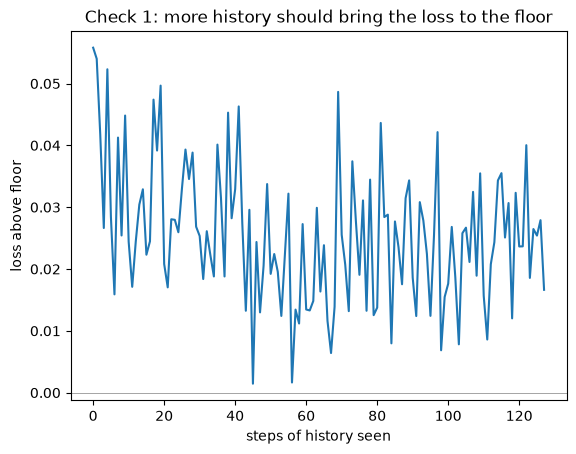

In [19]:
# ==== Cell 18: Check 1: does the loss approach the floor as the model sees more history? ====
W, L, _ = val_probs.shape
flat_states = val_states.reshape(-1, 19)
flat_eps = np.repeat(val_eps, L)

floor = true_entropy(flat_states, flat_eps).reshape(W, L)
nll = -np.log(np.take_along_axis(val_probs, val_acts[..., None], axis=-1)[..., 0] + 1e-12)
gap_by_pos = (nll - floor).mean(axis=0)            # (L,)

for t in [0, 1, 2, 4, 8, 16, 32, 64, L - 1]:
    print(f"history {t:>3} steps: loss above floor {gap_by_pos[t]:.4f}")

plt.plot(gap_by_pos)
plt.axhline(0, color="gray", lw=0.5)
plt.xlabel("steps of history seen")
plt.ylabel("loss above floor")
plt.title("Check 1: more history should bring the loss to the floor")
plt.show()

            t=0    t=8   t=32   t=64  t=127
true_eps                                   
0.1       0.479  0.331  0.258  0.263  0.254
0.2       0.517  0.397  0.317  0.316  0.286
0.3       0.563  0.420  0.399  0.386  0.368
0.4       0.574  0.527  0.492  0.483  0.469
0.5       0.623  0.582  0.562  0.554  0.559
0.6       0.605  0.631  0.644  0.656  0.672
0.7       0.658  0.692  0.703  0.700  0.729
0.8       0.688  0.729  0.766  0.778  0.816
0.9       0.723  0.757  0.814  0.843  0.861
1.0       0.719  0.832  0.844  0.870  0.883


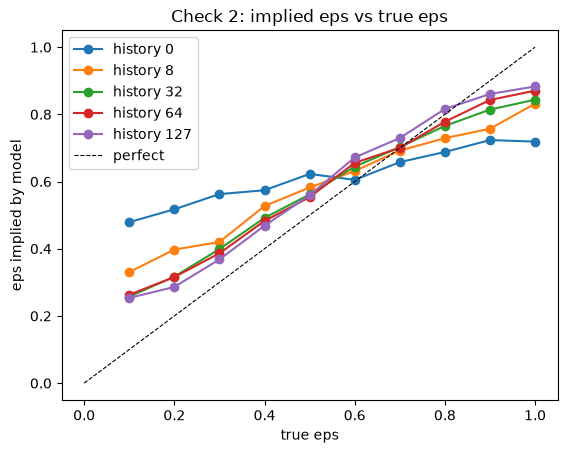

In [20]:
# ==== Cell 19: Check 2: can we read eps out of the model's predictions? ====
# On clear rows the true chance of the best move is 1 - 0.75 * eps,
# so the eps the model "believes" is (1 - p_best) / 0.75.
clear = (n_ties(flat_states) == 1).reshape(W, L)
best = best_dir(flat_states).reshape(W, L)
p_best = np.take_along_axis(val_probs, best[..., None], axis=-1)[..., 0]
eps_hat = np.clip((1 - p_best) / 0.75, 0, 1)

positions = [0, 8, 32, 64, L - 1]
rows = []
for e in np.unique(val_eps):
    row = {"true_eps": round(float(e), 1)}
    for t in positions:
        m = clear[:, t] & np.isclose(val_eps, e)
        row[f"t={t}"] = eps_hat[m, t].mean() if m.any() else np.nan
    rows.append(row)
table = pd.DataFrame(rows).set_index("true_eps")
print(table.round(3))

for t in positions:
    plt.plot(table.index, table[f"t={t}"], marker="o", label=f"history {t}")
plt.plot([0, 1], [0, 1], "k--", lw=0.8, label="perfect")
plt.xlabel("true eps")
plt.ylabel("eps implied by model")
plt.legend()
plt.title("Check 2: implied eps vs true eps")
plt.show()

In [21]:
# ==== Cell 19b: break the gap down ====
gap = nll - floor                                   # (W, L), from Cell 18
pred = val_probs.argmax(-1)                         # model's top move
eps_grid = np.unique(val_eps)

# Reference: best possible loss with NO history = true odds averaged over all eps values
p_mix = np.mean([true_probs(flat_states, np.full(len(flat_states), e)) for e in eps_grid], axis=0)
nll_mix = -np.log(p_mix[np.arange(len(p_mix)), val_acts.reshape(-1)] + 1e-12)
print(f"ideal gap with no history: {(nll_mix - floor.reshape(-1)).mean():.4f}   "
      f"(the model at history 0 should be close to this)\n")

# Smoothed over position ranges, plus how well the model follows the rule there
buckets = {"0": slice(0, 1), "1-7": slice(1, 8), "8-31": slice(8, 32),
           "32-63": slice(32, 64), "64-127": slice(64, 128)}
for name, sl in buckets.items():
    rule_ok = (pred[:, sl] == best[:, sl])[clear[:, sl]].mean()
    print(f"history {name:>6}: gap {gap[:, sl].mean():.4f}   rule agreement on clear rows {rule_ok:.4f}")

# Which eps values still have a large gap late in the window?
print()
late = slice(64, 128)
for e in eps_grid:
    m = np.isclose(val_eps, e)
    print(f"eps {e:.1f}: gap after 64+ steps {gap[m, late].mean():.4f}")

ideal gap with no history: 0.0459   (the model at history 0 should be close to this)

history      0: gap 0.0558   rule agreement on clear rows 0.9302
history    1-7: gap 0.0372   rule agreement on clear rows 0.9576
history   8-31: gap 0.0299   rule agreement on clear rows 0.9663
history  32-63: gap 0.0227   rule agreement on clear rows 0.9699
history 64-127: gap 0.0234   rule agreement on clear rows 0.9715

eps 0.1: gap after 64+ steps 0.0690
eps 0.2: gap after 64+ steps 0.0378
eps 0.3: gap after 64+ steps 0.0380
eps 0.4: gap after 64+ steps 0.0270
eps 0.5: gap after 64+ steps 0.0190
eps 0.6: gap after 64+ steps 0.0171
eps 0.7: gap after 64+ steps 0.0095
eps 0.8: gap after 64+ steps 0.0056
eps 0.9: gap after 64+ steps 0.0063
eps 1.0: gap after 64+ steps 0.0040


In [22]:
# ==== Cell 20: save both models ====
torch.save(step_model.state_dict(), OUT_DIR / "step_model.pt")
torch.save(seq_model.state_dict(), OUT_DIR / "seq_model.pt")
print("saved to", OUT_DIR)

saved to /home/spatel/Desktop/Projects/collective_intelligence/ant_sim/simple_ant_sim/data/simple_model


In [23]:
# ==== Cell 21 (optional): run the Step 0 model inside the simulator ====
import sys, types, copy
sys.path.insert(0, str(Path.cwd() / "simple_ant_sim"))
from simulation import Simulation
from config import Config

sim_mod = sys.modules[Simulation.__module__]
original_decide = sim_mod.decide
cpu_model = copy.deepcopy(step_model).cpu().eval()


@torch.no_grad()
def learned_decide(ant, local, rng, cfg):
    x = torch.from_numpy(normalize(ant.obs[None]))           # SAME normalize as training
    a_logit, p_logit, d_logit = cpu_model(x)
    if rng.random() < cfg.epsilon:
        d = int(rng.integers(N_ACTIONS))                       # random move
    else:
        prob = a_logit.softmax(-1)[0].numpy().astype(np.float64)
        d = int(rng.choice(N_ACTIONS, p=prob / prob.sum()))    # brain move (sampling splits ties)
    action = np.zeros(N_ACTIONS, dtype=np.float32)
    action[d] = 1.0
    return types.SimpleNamespace(action=action, pick=bool(p_logit.item() > 0),
                                 drop=bool(d_logit.item() > 0), mode="learned")


def run_sim(eps, seed, decide_fn, T=2000):
    sim_mod.decide = decide_fn
    try:
        sim = Simulation(Config(epsilon=eps, seed=seed))
        sim.world.add_food(80, 80, radius=4, amount_per_cell=5)   # match how training runs placed food
        sim.world.add_food(20, 75, radius=4, amount_per_cell=5)
        for _ in range(T):
            sim.step()
        return sim.world.food_delivered
    finally:
        sim_mod.decide = original_decide                       # always put the real brain back


torch.set_num_threads(1)     # one-row model calls are faster single-threaded
rows = []
for eps in [0.1, 0.3, 0.5]:
    for seed in range(10):
        rows.append(dict(eps=eps, seed=seed,
                         original=run_sim(eps, seed, original_decide),
                         learned=run_sim(eps, seed, learned_decide)))
        print(rows[-1])
print(pd.DataFrame(rows).groupby("eps")[["original", "learned"]].agg(["mean", "std"]))

{'eps': 0.1, 'seed': 0, 'original': 359, 'learned': 356}
{'eps': 0.1, 'seed': 1, 'original': 336, 'learned': 297}
{'eps': 0.1, 'seed': 2, 'original': 461, 'learned': 262}
{'eps': 0.1, 'seed': 3, 'original': 318, 'learned': 261}
{'eps': 0.1, 'seed': 4, 'original': 258, 'learned': 382}
{'eps': 0.1, 'seed': 5, 'original': 362, 'learned': 292}
{'eps': 0.1, 'seed': 6, 'original': 468, 'learned': 388}
{'eps': 0.1, 'seed': 7, 'original': 402, 'learned': 247}
{'eps': 0.1, 'seed': 8, 'original': 351, 'learned': 285}
{'eps': 0.1, 'seed': 9, 'original': 379, 'learned': 435}
{'eps': 0.3, 'seed': 0, 'original': 285, 'learned': 309}
{'eps': 0.3, 'seed': 1, 'original': 283, 'learned': 323}
{'eps': 0.3, 'seed': 2, 'original': 462, 'learned': 355}
{'eps': 0.3, 'seed': 3, 'original': 299, 'learned': 297}
{'eps': 0.3, 'seed': 4, 'original': 264, 'learned': 260}
{'eps': 0.3, 'seed': 5, 'original': 422, 'learned': 315}
{'eps': 0.3, 'seed': 6, 'original': 417, 'learned': 412}
{'eps': 0.3, 'seed': 7, 'origin

In [24]:
# ==== Cell 22 (control): train a model that sees ONLY the states ====
# X[..., :19] is a view, not a copy, so this uses no extra memory.
# No previous actions (and no brain odds if you use option 2), so it can only guess eps from the states.
seq_ctrl = {split: (X[..., :19], Y, EPS) for split, (X, Y, EPS) in seq.items()}

ctrl_model = AntGPT(d_in=19).to(DEVICE)
train_seq_model(ctrl_model, seq_ctrl["train"], SEQ_EPOCHS, SEQ_BATCH, SEQ_LR)
ctrl_probs, ctrl_acts, ctrl_states, ctrl_eps = collect_seq(ctrl_model, seq_ctrl["val"])

  epoch 1  batch 0  loss 1.5011
  epoch 1  batch 100  loss 1.3781
  epoch 1  batch 200  loss 1.3276
  epoch 1  batch 300  loss 1.2923
  epoch 1  batch 400  loss 1.2669
  epoch 1  batch 500  loss 1.2543
epoch 1 done in 9 s
  epoch 2  batch 0  loss 1.2706
  epoch 2  batch 100  loss 1.2401
  epoch 2  batch 200  loss 1.2347
  epoch 2  batch 300  loss 1.2295
  epoch 2  batch 400  loss 1.2199
  epoch 2  batch 500  loss 1.2146
epoch 2 done in 9 s
  epoch 3  batch 0  loss 1.2327
  epoch 3  batch 100  loss 1.2127
  epoch 3  batch 200  loss 1.2075
  epoch 3  batch 300  loss 1.2064
  epoch 3  batch 400  loss 1.2059
  epoch 3  batch 500  loss 1.2004
epoch 3 done in 9 s
  epoch 4  batch 0  loss 1.2210
  epoch 4  batch 100  loss 1.2027
  epoch 4  batch 200  loss 1.1969
  epoch 4  batch 300  loss 1.1963
  epoch 4  batch 400  loss 1.1940
  epoch 4  batch 500  loss 1.1932
epoch 4 done in 9 s
  epoch 5  batch 0  loss 1.2150
  epoch 5  batch 100  loss 1.1940
  epoch 5  batch 200  loss 1.1928
  epoch 5  b

In [25]:
# ==== Cell 23 (control): compare implied eps, main model vs states-only ====
def implied_eps_table(probs, states, eps, positions=(0, 8, 32, 64, SEQ_LEN - 1)):
    W, L, _ = probs.shape
    s = states.reshape(-1, 19)
    clear = (n_ties(s) == 1).reshape(W, L)
    best = best_dir(s).reshape(W, L)
    p_best = np.take_along_axis(probs, best[..., None], axis=-1)[..., 0]
    eps_hat = np.clip((1 - p_best) / 0.75, 0, 1)
    rows = []
    for e in np.unique(eps):
        row = {"true_eps": round(float(e), 1)}
        for t in positions:
            m = clear[:, t] & np.isclose(eps, e)
            row[f"t={t}"] = eps_hat[m, t].mean() if m.any() else np.nan
        rows.append(row)
    return pd.DataFrame(rows).set_index("true_eps")


print("main model (states + history of actions):")
print(implied_eps_table(val_probs, val_states, val_eps).round(3))
print("\nstates-only control:")
print(implied_eps_table(ctrl_probs, ctrl_states, ctrl_eps).round(3))

main model (states + history of actions):
            t=0    t=8   t=32   t=64  t=127
true_eps                                   
0.1       0.479  0.331  0.258  0.263  0.254
0.2       0.517  0.397  0.317  0.316  0.286
0.3       0.563  0.420  0.399  0.386  0.368
0.4       0.574  0.527  0.492  0.483  0.469
0.5       0.623  0.582  0.562  0.554  0.559
0.6       0.605  0.631  0.644  0.656  0.672
0.7       0.658  0.692  0.703  0.700  0.729
0.8       0.688  0.729  0.766  0.778  0.816
0.9       0.723  0.757  0.814  0.843  0.861
1.0       0.719  0.832  0.844  0.870  0.883

states-only control:
            t=0    t=8   t=32   t=64  t=127
true_eps                                   
0.1       0.567  0.371  0.295  0.260  0.262
0.2       0.592  0.458  0.341  0.340  0.300
0.3       0.612  0.450  0.416  0.412  0.371
0.4       0.629  0.534  0.513  0.505  0.469
0.5       0.670  0.589  0.569  0.565  0.562
0.6       0.646  0.608  0.644  0.646  0.663
0.7       0.678  0.664  0.682  0.698  0.734
0.8       0.

In [26]:
# ==== Cell 24 (option 2): sequences where each token also carries the Step 0 model's odds ====
@torch.no_grad()
def brain_probs(states_norm, batch=65536):
    """Step 0 model's predicted odds for each state. Input (..., 19) normalized, output (..., 4)."""
    step_model.eval()
    shape = states_norm.shape[:-1]
    flat_s = torch.from_numpy(np.ascontiguousarray(states_norm.reshape(-1, 19)))
    out = []
    for start in range(0, len(flat_s), batch):
        a_logit, _, _ = step_model(flat_s[start:start + batch].to(DEVICE))
        out.append(a_logit.softmax(-1).cpu().numpy())
    return np.concatenate(out).reshape(*shape, 4).astype(np.float32)


# X2[i, t] = [normalized state (19), brain odds (4), one-hot previous action (4)]  -> 27 numbers
def build_sequences_with_rule(run_list):
    X, Y, EPS = [], [], []
    for r in run_list:
        s = normalize(r["state"])                                              # (T, N, 19)
        x = np.concatenate([s, brain_probs(s), r["prev_action"]], axis=-1)     # (T, N, 27)
        X.append(x.transpose(1, 0, 2))
        Y.append(r["action"].T)
        EPS.append(np.full(x.shape[1], r["eps"], dtype=np.float32))
    return np.concatenate(X), np.concatenate(Y), np.concatenate(EPS)


# train and val only, to save memory (about 1 GB for train)
seq2 = {split: build_sequences_with_rule(runs[split]) for split in ["train", "val"]}
for split, (X, Y, EPS) in seq2.items():
    print(f"{split}: X {X.shape}  Y {Y.shape}")

train: X (6000, 1500, 27)  Y (6000, 1500)
val: X (2000, 1500, 27)  Y (2000, 1500)


In [27]:
# ==== Cell 25 (option 2): train the model that is given the rule ====
seq_model2 = AntGPT(d_in=27).to(DEVICE)
train_seq_model(seq_model2, seq2["train"], SEQ_EPOCHS, SEQ_BATCH, SEQ_LR)
torch.save(seq_model2.state_dict(), OUT_DIR / "seq_model2_with_rule.pt")

  epoch 1  batch 0  loss 1.4952
  epoch 1  batch 100  loss 1.3215
  epoch 1  batch 200  loss 1.2130
  epoch 1  batch 300  loss 1.1986
  epoch 1  batch 400  loss 1.1929
  epoch 1  batch 500  loss 1.1883
epoch 1 done in 9 s
  epoch 2  batch 0  loss 1.2178
  epoch 2  batch 100  loss 1.1830
  epoch 2  batch 200  loss 1.1847
  epoch 2  batch 300  loss 1.1832
  epoch 2  batch 400  loss 1.1793
  epoch 2  batch 500  loss 1.1767
epoch 2 done in 9 s
  epoch 3  batch 0  loss 1.1811
  epoch 3  batch 100  loss 1.1707
  epoch 3  batch 200  loss 1.1721
  epoch 3  batch 300  loss 1.1705
  epoch 3  batch 400  loss 1.1703
  epoch 3  batch 500  loss 1.1681
epoch 3 done in 9 s
  epoch 4  batch 0  loss 1.1217
  epoch 4  batch 100  loss 1.1649
  epoch 4  batch 200  loss 1.1653
  epoch 4  batch 300  loss 1.1677
  epoch 4  batch 400  loss 1.1711
  epoch 4  batch 500  loss 1.1645
epoch 4 done in 9 s
  epoch 5  batch 0  loss 1.1575
  epoch 5  batch 100  loss 1.1674
  epoch 5  batch 200  loss 1.1636
  epoch 5  b

In [28]:
# ==== Cell 26: predictions from BOTH models on the SAME validation windows ====
# collect_seq picks windows with a fixed seed, so both models see identical ant histories.
v1 = collect_seq(seq_model, seq["val"])      # option 1: learns the rule itself
v2 = collect_seq(seq_model2, seq2["val"])    # option 2: given the rule

assert np.array_equal(v1[1], v2[1]), "windows differ between the two models"
assert np.allclose(v1[2], v2[2]), "states differ between the two models"
print("same", v1[0].shape[0], "windows for both models")

same 3000 windows for both models


In [29]:
# ==== Cell 27: one analysis function for any sequence model ====
BUCKETS = {"0": slice(0, 1), "1-7": slice(1, 8), "8-31": slice(8, 32),
           "32-63": slice(32, 64), "64-127": slice(64, SEQ_LEN)}
RULE_EPS_MAX = 0.7   # at eps near 1.0 the correct prediction is nearly uniform, so "agrees with rule" means nothing there


def summarize_model(probs, acts, states, eps):
    """Returns (by_history, by_eps, scores) for one model's predictions on validation windows."""
    W, L, _ = probs.shape
    s = states.reshape(-1, 19)
    rows_eps = np.repeat(eps, L)

    # loss above the best possible (floor = loss of a model that knows the true eps)
    floor = true_entropy(s, rows_eps).reshape(W, L)
    nll = -np.log(np.take_along_axis(probs, acts[..., None], axis=-1)[..., 0] + 1e-12)
    gap = nll - floor

    # rule following and implied eps, on clear-choice rows
    clear = (n_ties(s) == 1).reshape(W, L)
    best = best_dir(s).reshape(W, L)
    rule_ok = probs.argmax(-1) == best
    p_best = np.take_along_axis(probs, best[..., None], axis=-1)[..., 0]
    eps_hat = np.clip((1 - p_best) / 0.75, 0, 1)
    rule_rows = clear & (eps <= RULE_EPS_MAX + 1e-6)[:, None]

    # 1) averaged over history ranges (smoother than single positions)
    by_history = pd.DataFrame([
        dict(history=name, gap=gap[:, sl].mean(),
             rule_agreement=rule_ok[:, sl][rule_rows[:, sl]].mean())
        for name, sl in BUCKETS.items()
    ]).set_index("history")

    # 2) implied eps per true eps, per history range
    rows = []
    for e in np.unique(eps):
        m = np.isclose(eps, e)
        row = {"true_eps": round(float(e), 1)}
        for name, sl in BUCKETS.items():
            row[name] = eps_hat[m, sl][clear[m, sl]].mean()
        row["late_gap"] = gap[m, BUCKETS["64-127"]].mean()
        rows.append(row)
    by_eps = pd.DataFrame(rows).set_index("true_eps")

    # 3) headline numbers
    late = by_eps["64-127"]
    true = late.index.values
    clean = true <= 0.7
    slope, intercept = np.polyfit(true, late.values, 1)

    eps_grid = np.unique(eps)
    p_mix = np.mean([true_probs(s, np.full(len(s), e)) for e in eps_grid], axis=0)
    nll_mix = -np.log(p_mix[np.arange(len(s)), acts.reshape(-1)] + 1e-12)

    scores = {
        "gap, no-history ideal": (nll_mix - floor.reshape(-1)).mean(),
        "gap, history 0": gap[:, 0].mean(),
        "gap, history 64-127": gap[:, BUCKETS["64-127"]].mean(),
        "rule agreement, 64-127 (eps<=0.7)": by_history.loc["64-127", "rule_agreement"],
        "eps error, all eps": np.abs(late.values - true).mean(),
        "eps error, eps <= 0.7": np.abs(late.values[clean] - true[clean]).mean(),
        "eps slope (want 1)": slope,
        "eps intercept (want 0)": intercept,
    }
    return by_history, by_eps, scores

===== headline scores =====
                                   option 1 (learns rule)  \
gap, no-history ideal                              0.0459   
gap, history 0                                     0.0558   
gap, history 64-127                                0.0234   
rule agreement, 64-127 (eps<=0.7)                  0.9735   
eps error, all eps                                 0.0724   
eps error, eps <= 0.7                              0.0780   
eps slope (want 1)                                 0.7578   
eps intercept (want 0)                             0.1706   

                                   option 2 (given rule)  
gap, no-history ideal                             0.0459  
gap, history 0                                    0.0307  
gap, history 64-127                               0.0100  
rule agreement, 64-127 (eps<=0.7)                 0.9993  
eps error, all eps                                0.0384  
eps error, eps <= 0.7                             0.0186  
eps slope

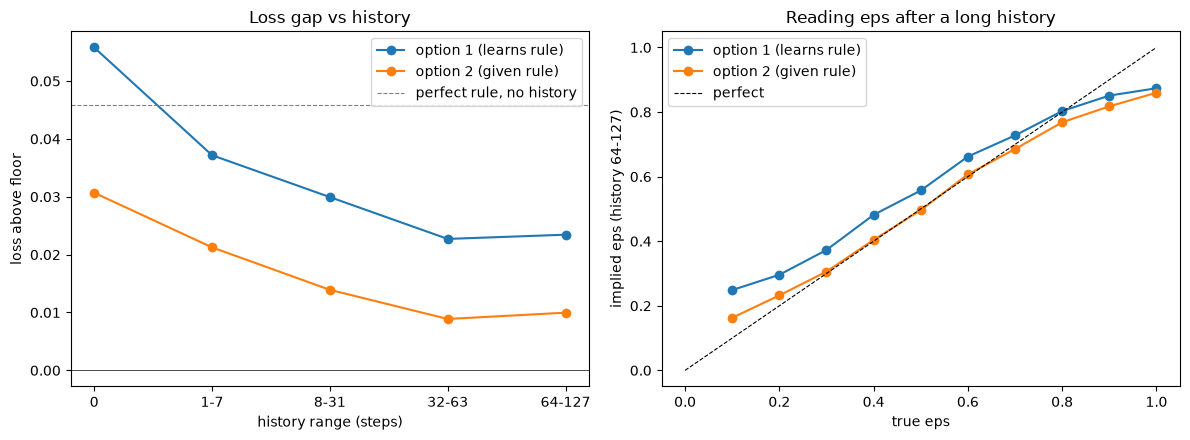

In [30]:
# ==== Cell 28: compare option 1 vs option 2 ====
results = {
    "option 1 (learns rule)": summarize_model(*v1),
    "option 2 (given rule)": summarize_model(*v2),
}

print("===== headline scores =====")
print(pd.DataFrame({name: r[2] for name, r in results.items()}).round(4))

print("\n===== by history =====")
print(pd.concat({name: r[0] for name, r in results.items()}, axis=1).round(4))

print("\n===== implied eps by true eps =====")
print(pd.concat({name: r[1][["0", "8-31", "64-127", "late_gap"]] for name, r in results.items()},
                axis=1).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, (by_history, by_eps, _) in results.items():
    axes[0].plot(by_history.index, by_history["gap"], marker="o", label=name)
    axes[1].plot(by_eps.index, by_eps["64-127"], marker="o", label=name)

ideal = next(iter(results.values()))[2]["gap, no-history ideal"]
axes[0].axhline(ideal, color="gray", ls="--", lw=0.8, label="perfect rule, no history")
axes[0].axhline(0, color="black", lw=0.5)
axes[0].set_xlabel("history range (steps)")
axes[0].set_ylabel("loss above floor")
axes[0].set_title("Loss gap vs history")
axes[0].legend()

axes[1].plot([0, 1], [0, 1], "k--", lw=0.8, label="perfect")
axes[1].set_xlabel("true eps")
axes[1].set_ylabel("implied eps (history 64-127)")
axes[1].set_title("Reading eps after a long history")
axes[1].legend()
plt.tight_layout()
plt.show()

In [31]:
# ==== Cell 31: which part of the learned brain causes the low-eps gap? ====
def original_but_relabeled(ant, local, rng, cfg):
    """The REAL brain's decision, returned the way learned_decide returns it (mode='learned')."""
    dec = original_decide(ant, local, rng, cfg)
    return types.SimpleNamespace(action=dec.action, pick=dec.pick, drop=dec.drop, mode="learned")


@torch.no_grad()
def learned_decide_top(ant, local, rng, cfg):
    """Learned brain, but takes its top choice (random among near-ties) instead of sampling."""
    x = torch.from_numpy(normalize(ant.obs[None]))
    a_logit, p_logit, d_logit = cpu_model(x)
    if rng.random() < cfg.epsilon:
        d = int(rng.integers(N_ACTIONS))
    else:
        prob = a_logit.softmax(-1)[0].numpy()
        d = int(rng.choice(np.flatnonzero(prob >= prob.max() - 1e-3)))
    action = np.zeros(N_ACTIONS, dtype=np.float32)
    action[d] = 1.0
    return types.SimpleNamespace(action=action, pick=bool(p_logit.item() > 0),
                                 drop=bool(d_logit.item() > 0), mode="learned")


brains = {"original": original_decide,
          "original, relabeled": original_but_relabeled,
          "learned (samples)": learned_decide,
          "learned (top choice)": learned_decide_top}

rows = []
for seed in range(10):
    row = {"seed": seed}
    for name, fn in brains.items():
        row[name] = run_sim(0.1, seed, fn)
    rows.append(row)
    print(row)

print(pd.DataFrame(rows).drop(columns="seed").agg(["mean", "std"]).round(1))

{'seed': 0, 'original': 359, 'original, relabeled': 359, 'learned (samples)': 356, 'learned (top choice)': 262}
{'seed': 1, 'original': 336, 'original, relabeled': 336, 'learned (samples)': 297, 'learned (top choice)': 300}
{'seed': 2, 'original': 461, 'original, relabeled': 461, 'learned (samples)': 262, 'learned (top choice)': 410}
{'seed': 3, 'original': 318, 'original, relabeled': 318, 'learned (samples)': 261, 'learned (top choice)': 301}
{'seed': 4, 'original': 258, 'original, relabeled': 258, 'learned (samples)': 382, 'learned (top choice)': 288}
{'seed': 5, 'original': 362, 'original, relabeled': 362, 'learned (samples)': 292, 'learned (top choice)': 361}
{'seed': 6, 'original': 468, 'original, relabeled': 468, 'learned (samples)': 388, 'learned (top choice)': 353}
{'seed': 7, 'original': 402, 'original, relabeled': 402, 'learned (samples)': 247, 'learned (top choice)': 266}
{'seed': 8, 'original': 351, 'original, relabeled': 351, 'learned (samples)': 285, 'learned (top choice)

In [32]:
# ==== Cell 32: is the learned brain truly uniform when the rule says "no signal"? ====
f = flat["val"]
probs, _, _ = predict_step_model(step_model, f)
s = f["state"]

no_signal = n_ties(s) == 4
p = probs[no_signal]
spread = p.max(1) - p.min(1)
print(f"no-signal rows: {no_signal.mean():.3f}")
print(f"mean top prob on no-signal rows:   {p.max(1).mean():.4f}   (want 0.25)")
print(f"rows where top - bottom > 0.001:   {(spread > 1e-3).mean():.3f}")
print(f"rows where top - bottom > 0.02:    {(spread > 0.02).mean():.3f}")

# Does the tilt follow the smell the rule IGNORES?
s_ns = s[no_signal]
carrying = s_ns[:, CARRYING] > 0.5
ignored = np.where(carrying[:, None], s_ns[:, SMELL_FOOD], s_ns[:, SMELL_HOME])
has_dir = ignored.max(1) > ignored.min(1)
toward = p.argmax(1) == ignored.argmax(1)
away = p.argmax(1) == ignored.argmin(1)
print(f"\nno-signal rows where the ignored smell points somewhere: {has_dir.mean():.3f}")
print(f"model's top pick points TOWARD the ignored smell: {toward[has_dir].mean():.3f}   (0.25 = no tilt)")
print(f"model's top pick points AWAY from it:             {away[has_dir].mean():.3f}")

no-signal rows: 0.468
mean top prob on no-signal rows:   0.2500   (want 0.25)
rows where top - bottom > 0.001:   0.000
rows where top - bottom > 0.02:    0.000

no-signal rows where the ignored smell points somewhere: 0.853
model's top pick points TOWARD the ignored smell: 0.254   (0.25 = no tilt)
model's top pick points AWAY from it:             0.322
